# Sniff fields by position (search epoch)

The sniff field of `sniff_raster.py` (firing rate by latency from inhalation and sniff frequency) computed separately
for each arena bin, over the sniffs whose inhalation falls in that bin. The bins are the 3 (x) x 7 (y) bins of
`position_locking.py`. Panels tile the arena with no gaps, each sized in proportion to its bin, and the top and
right axes give arena coordinates (px). The inset in each panel's upper right gives the bin and its number of sniffs. Only search sniffs are used
(inhalation and window end both in the epoch, as in `position_locking.py`). Bins with fewer than 100 sniffs are left
grey. Each panel has its own color scale (spikes per s); the small colorbar under the sniff count gives its min
and max. The max projections are left out to keep the panels readable.

- **black curve**: the next inhalation (latency = 1 / sniff frequency). Latencies past it are blank.
- **dashed line** (toggle with `show_deflection`): latency of the largest post-inhalation deflection. This is the
  bin's latency profile (rate vs latency over all of its sniffs; 10 ms bins smoothed over 1 bin, ignoring latencies
  that fewer than half of the bin's sniffs reach) minus its mean, at its maximum (peak) or minimum (trough). Which of
  the two is chosen once per unit: whichever deflection is larger in the profile over all of the epoch's sniffs. That
  way every bin is compared peak to peak or trough to trough. The label beside the line gives the latency and the
  size relative to the mean. Bins with < 50
  spikes get no line.

Titles give the same scores as `3_position_raster.ipynb`: **temporal_info z** (`info_z` from `sniff_locking.py`, search sniffs) and
**position_timing z** (`timing_z` from `position_locking.py`, search sniffs).

The plotting code lives in `position_field.py`.

In [1]:
import sys
sys.path.insert(0, 'sniff-raster-python')  # the analysis modules live there
import numpy as np
import pandas as pd
import position_locking as pl
from flip_state_plots import title_stats
from position_field import FieldSession, plot_position_field

EPOCH = 'search'
SHOW_DEFLECTION = True  # default for the dashed line at each bin's largest post-inhalation deflection
keys = ['mouse', 'session', 'region', 'cluster']
scores = pd.read_csv(f"{pl.OUT_FILE[:-len('.csv')]}_{EPOCH}.csv")
sniff_lock = pd.read_csv('E:/cbm-odor/sniff/sniff_locking.csv')
for d in (scores, sniff_lock):
    d['mouse'] = d['mouse'].astype(str)
scores = scores.merge(sniff_lock[keys + ['info_z', 'info_p', 'peak_latency_ms']], on=keys, how='left', validate='one_to_one')

sessions = {}  # loaded sessions, so units of the same session share one load


def position_field(mouse, session, cluster, region='ob', save_path=None, show_deflection=None):
    """Sniff field of one unit in each arena bin (search sniffs). Returns the latency (ms) and signed size (Hz)
    of each bin's largest peak or trough (whichever dominates over all sniffs), one row per y bin, one column per x bin."""
    key = (str(mouse), session, region)
    if key not in sessions:
        sessions[key] = FieldSession(*key[:2], EPOCH, region)
    row = scores[(scores['mouse'] == key[0]) & (scores['session'] == session) & (scores['region'] == region)
                 & (scores['cluster'] == cluster)]
    stats = '' if row.empty else title_stats(row['info_z'].iat[0], row['timing_z'].iat[0])
    show = SHOW_DEFLECTION if show_deflection is None else show_deflection
    latency, size, polarity = plot_position_field(sessions[key], int(cluster), stats, save_path, show_deflection=show)
    cols = pd.MultiIndex.from_product([['latency_ms', 'size_hz'], [f'x{i}' for i in range(latency.shape[0])]])
    return pd.DataFrame(np.hstack([latency.T, size.T]), columns=cols).rename_axis('y bin').round(1)

## Units whose sniff-locking depends most on position

Sniff-locked OB units (search `info_p < 0.05`) with at least 2,000 spikes in the search sniff windows,
ranked by search `interaction_z`, the same ranking as `3_position_raster.ipynb`.

,mouse,session,region,cluster,n_sniffs,n_spikes_used,info_z,peak_latency_ms,interaction_z,timing_z
821,9005,x3,ob,11,15075,37742,43.559069,94.0,19.954992,6.156004
793,9005,x11,ob,15,14127,41901,142.999323,114.0,19.837099,12.109208
844,9005,x4,ob,23,14533,54398,354.818233,152.0,18.780804,3.902071
831,9005,x3,ob,26,15075,50337,19.967850,108.0,18.331541,8.131198
822,9005,x3,ob,14,15075,47237,28.471902,112.0,18.121650,5.365250


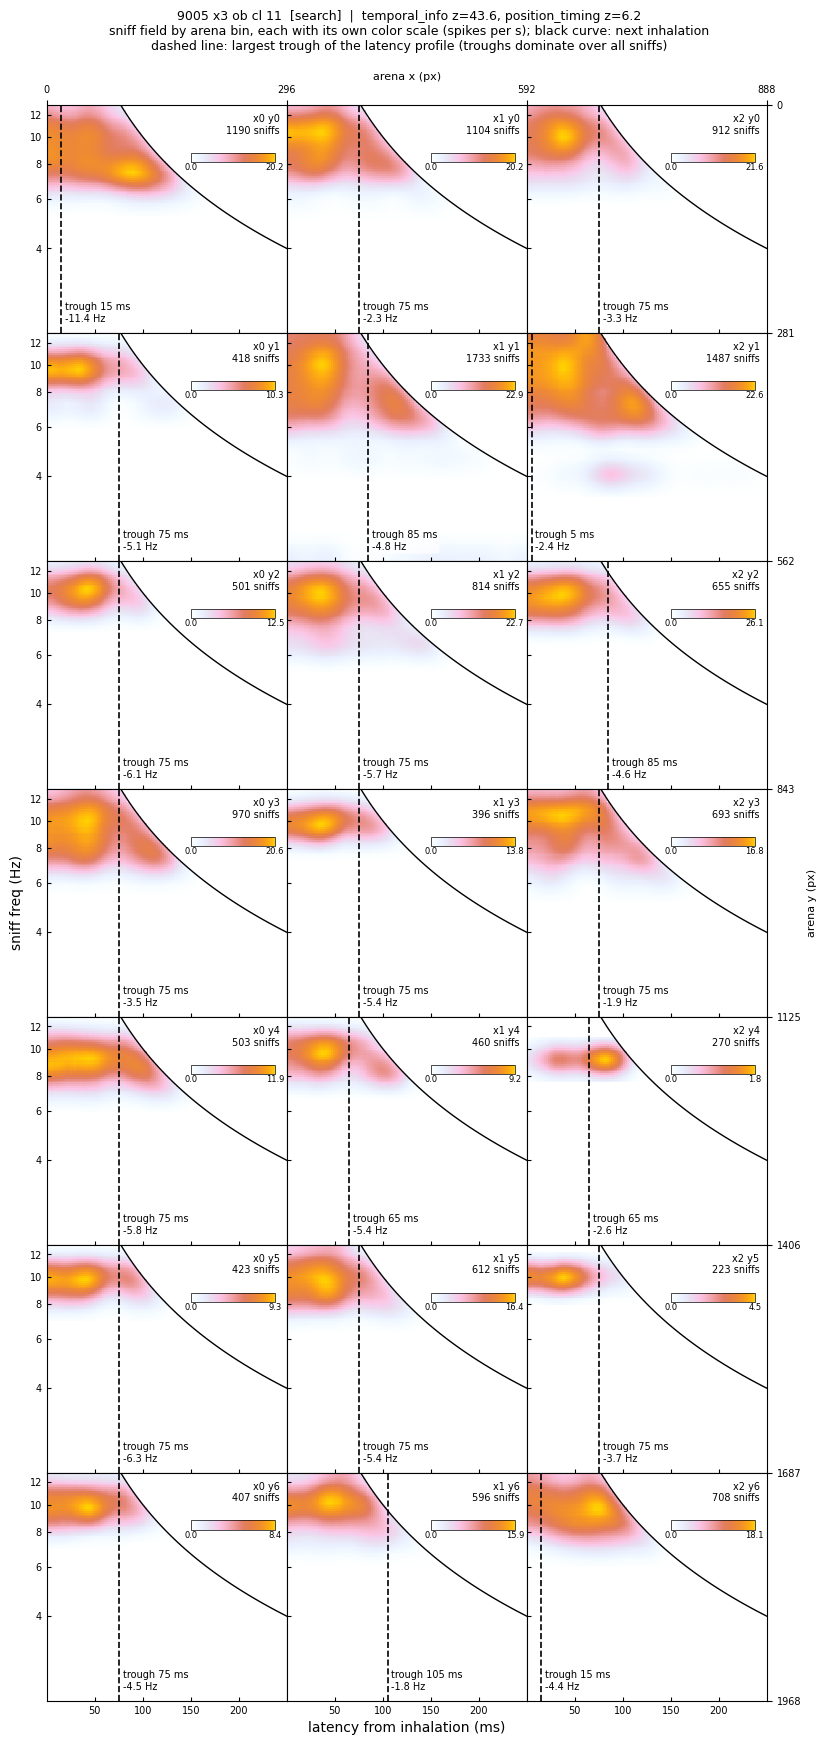

latency_ms              size_hz          
              x0     x1    x2      x0   x1   x2
y bin                                          
0           15.0   75.0  75.0   -11.4 -2.3 -3.3
1           75.0   85.0   5.0    -5.1 -4.8 -2.4
2           75.0   75.0  85.0    -6.1 -5.7 -4.6
3           75.0   75.0  75.0    -3.5 -5.4 -1.9
4           75.0   65.0  65.0    -5.8 -5.4 -2.6
5           75.0   75.0  75.0    -6.3 -5.4 -3.7
6           75.0  105.0  15.0    -4.5 -1.8 -4.4

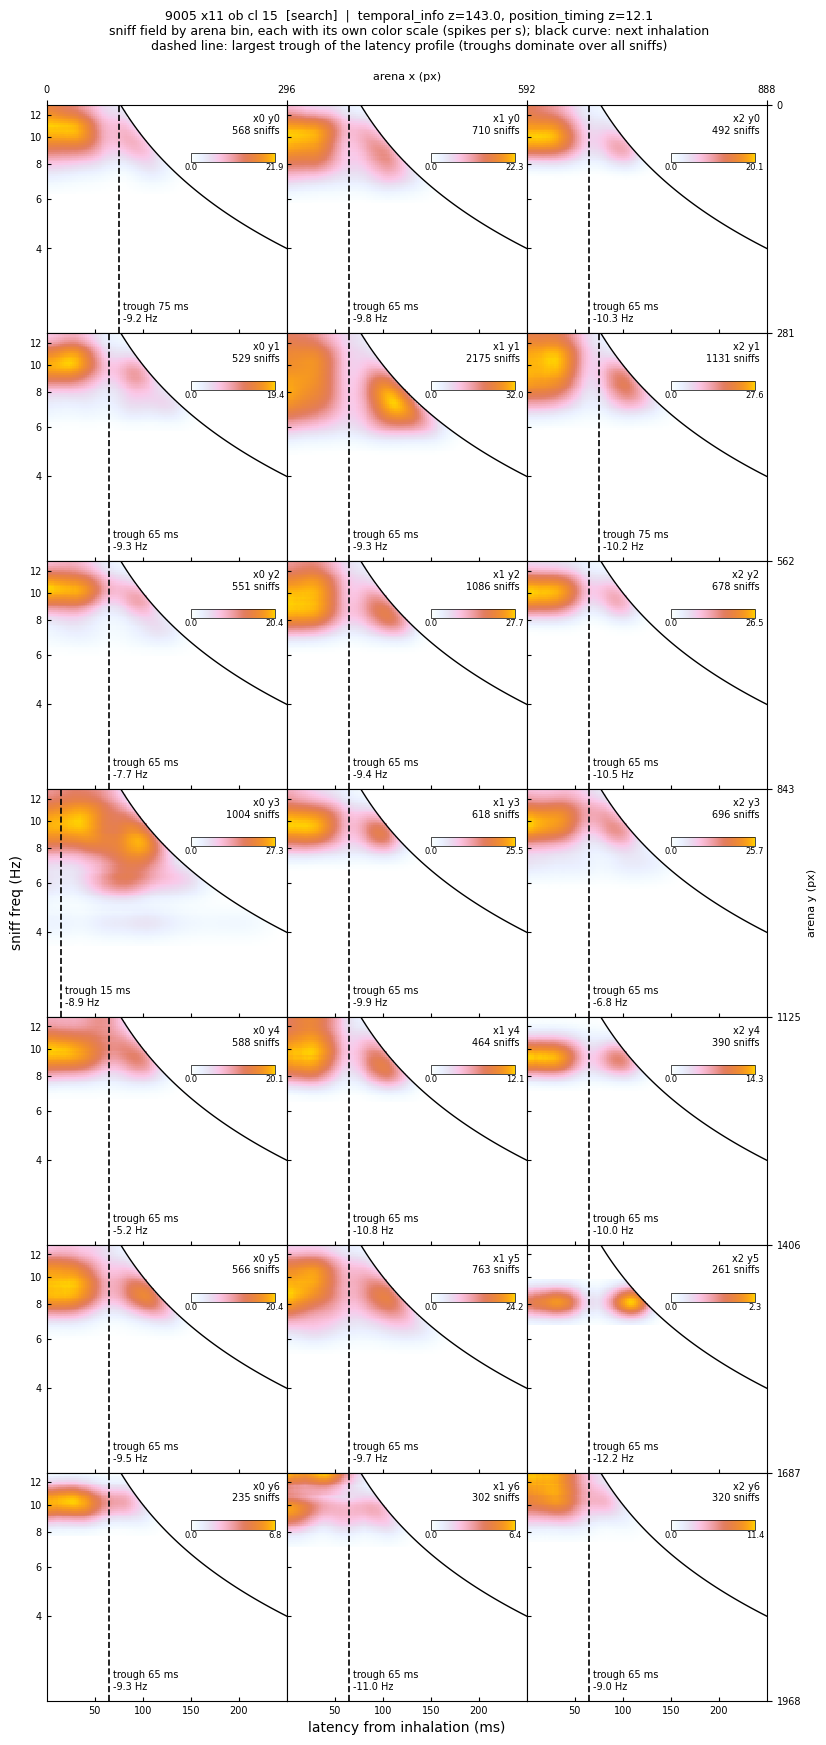

latency_ms             size_hz            
              x0    x1    x2      x0    x1    x2
y bin                                           
0           75.0  65.0  65.0    -9.2  -9.8 -10.3
1           65.0  65.0  75.0    -9.3  -9.3 -10.2
2           65.0  65.0  65.0    -7.7  -9.4 -10.5
3           15.0  65.0  65.0    -8.9  -9.9  -6.8
4           65.0  65.0  65.0    -5.2 -10.8 -10.0
5           65.0  65.0  65.0    -9.5  -9.7 -12.2
6           65.0  65.0  65.0    -9.3 -11.0  -9.0

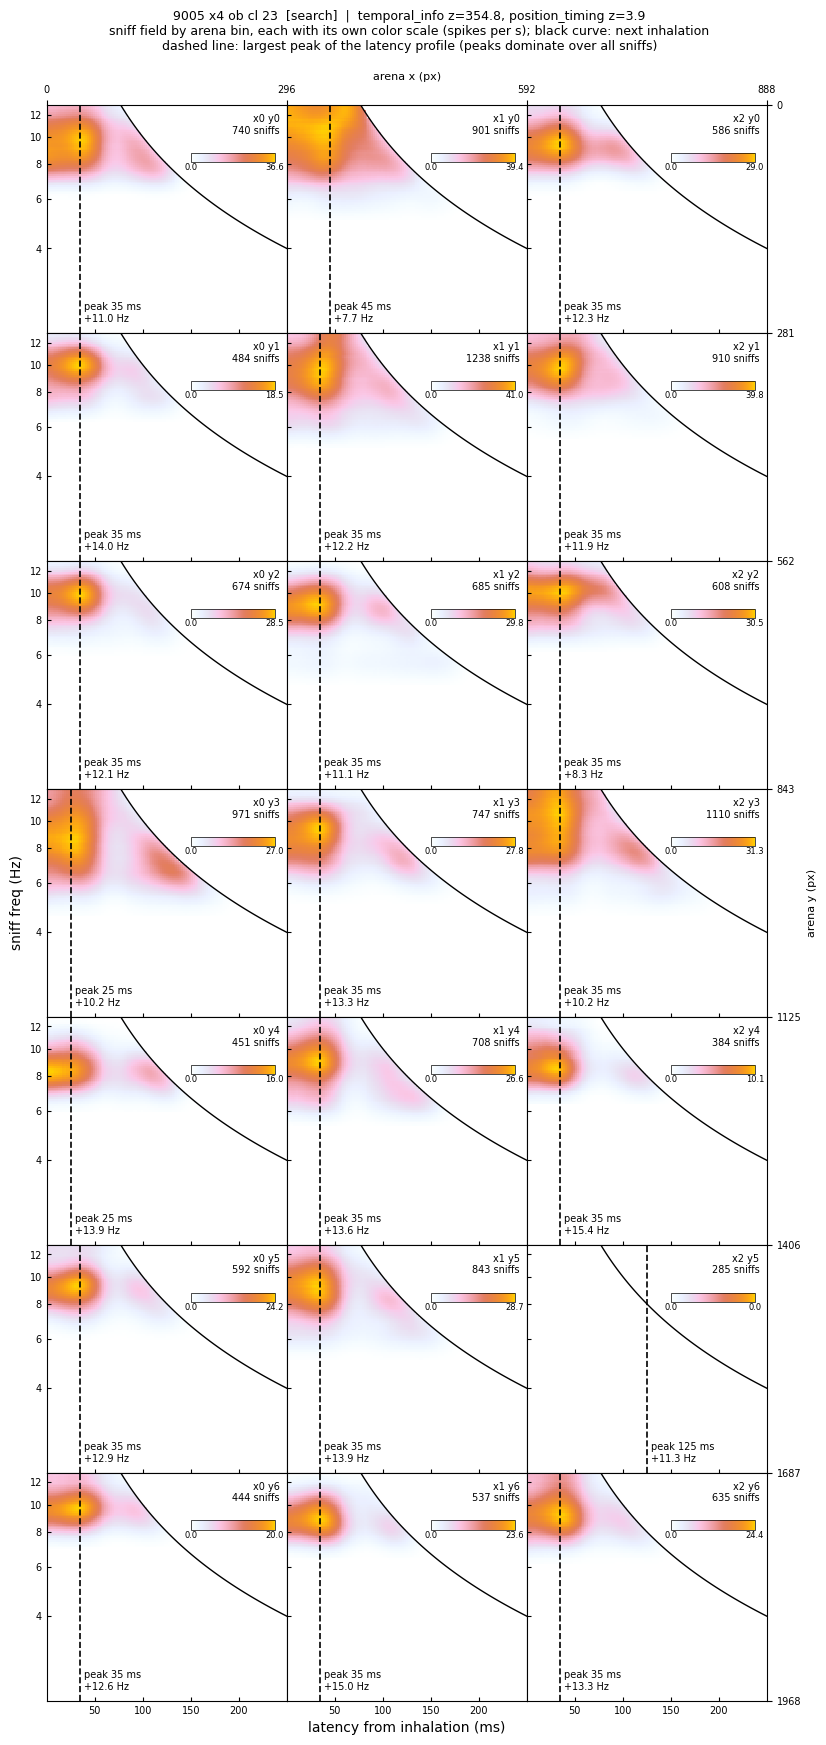

latency_ms              size_hz            
              x0    x1     x2      x0    x1    x2
y bin                                            
0           35.0  45.0   35.0    11.0   7.7  12.3
1           35.0  35.0   35.0    14.0  12.2  11.9
2           35.0  35.0   35.0    12.1  11.1   8.3
3           25.0  35.0   35.0    10.2  13.3  10.2
4           25.0  35.0   35.0    13.9  13.6  15.4
5           35.0  35.0  125.0    12.9  13.9  11.3
6           35.0  35.0   35.0    12.6  15.0  13.3

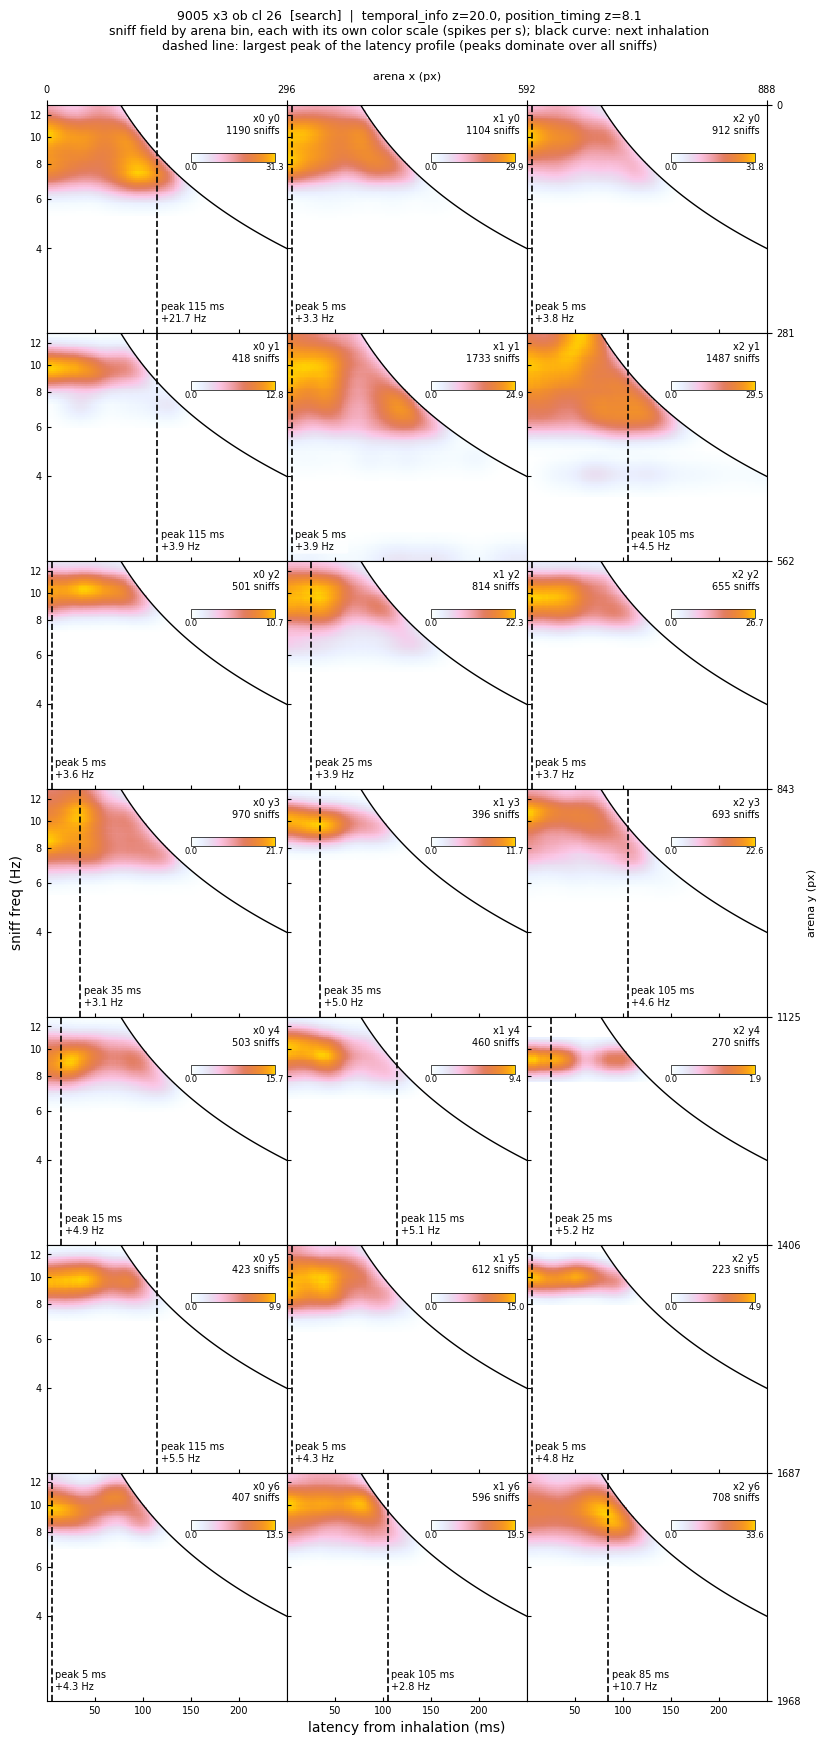

latency_ms               size_hz           
              x0     x1     x2      x0   x1    x2
y bin                                            
0          115.0    5.0    5.0    21.7  3.3   3.8
1          115.0    5.0  105.0     3.9  3.9   4.5
2            5.0   25.0    5.0     3.6  3.9   3.7
3           35.0   35.0  105.0     3.1  5.0   4.6
4           15.0  115.0   25.0     4.9  5.1   5.2
5          115.0    5.0    5.0     5.5  4.3   4.8
6            5.0  105.0   85.0     4.3  2.8  10.7

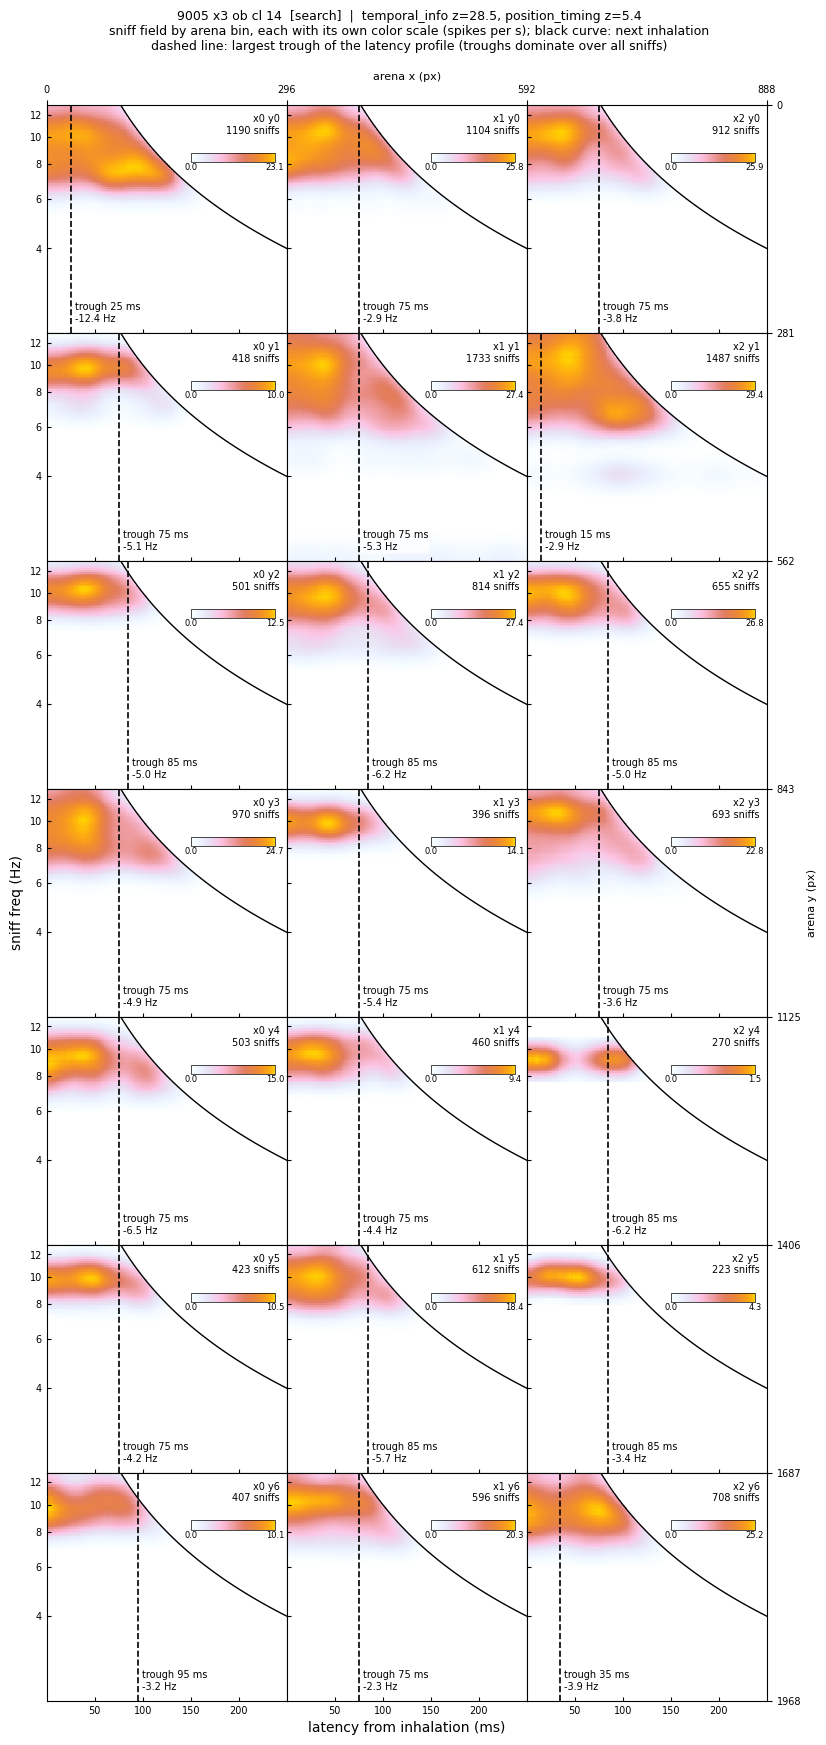

latency_ms             size_hz          
              x0    x1    x2      x0   x1   x2
y bin                                         
0           25.0  75.0  75.0   -12.4 -2.9 -3.8
1           75.0  75.0  15.0    -5.1 -5.3 -2.9
2           85.0  85.0  85.0    -5.0 -6.2 -5.0
3           75.0  75.0  75.0    -4.9 -5.4 -3.6
4           75.0  75.0  85.0    -6.5 -4.4 -6.2
5           75.0  85.0  85.0    -4.2 -5.7 -3.4
6           95.0  75.0  35.0    -3.2 -2.3 -3.9

In [2]:
N_UNITS = 5
MIN_SPIKES_RANK = 2000

top = scores[(scores['info_p'] < 0.05) & (scores['n_spikes_used'] >= MIN_SPIKES_RANK)].sort_values('interaction_z', ascending=False)
display(top[keys + ['n_sniffs', 'n_spikes_used', 'info_z', 'peak_latency_ms', 'interaction_z', 'timing_z']].head(N_UNITS))
for _, u in top.head(N_UNITS).iterrows():
    display(position_field(u['mouse'], u['session'], u['cluster'], u['region']))

## Any unit

`position_field(mouse, session, cluster, region='ob', save_path=None, show_deflection=None)` plots one unit and
returns each bin's deflection latency and size. `show_deflection` overrides `SHOW_DEFLECTION` for one call. Pass
`save_path` to also write a PNG.

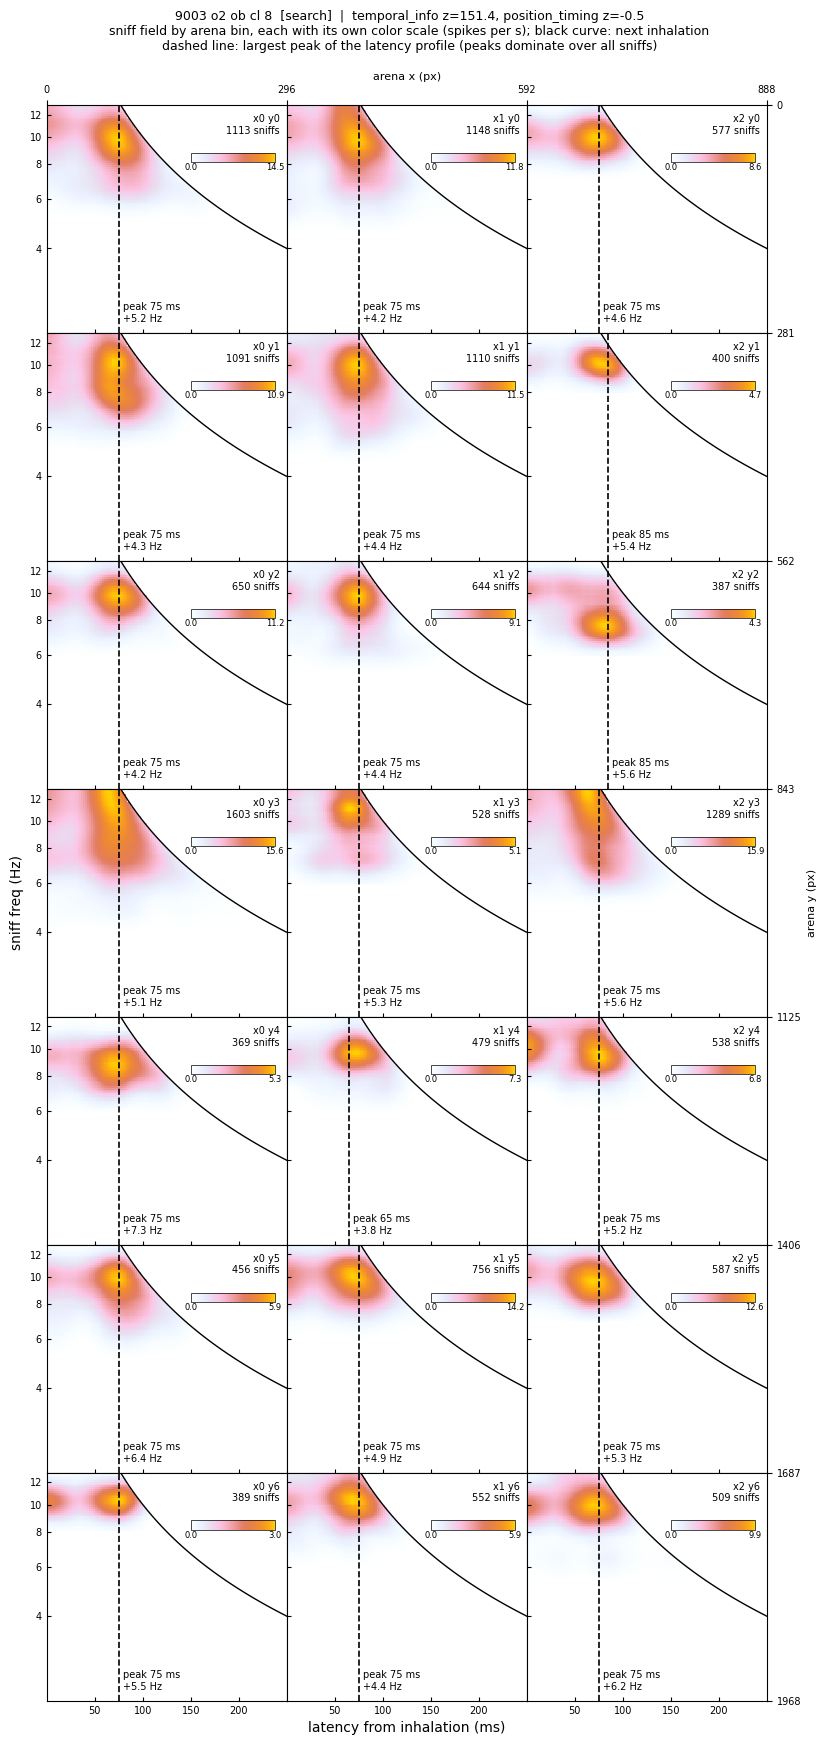

latency_ms             size_hz          
              x0    x1    x2      x0   x1   x2
y bin                                         
0           75.0  75.0  75.0     5.2  4.2  4.6
1           75.0  75.0  85.0     4.3  4.4  5.4
2           75.0  75.0  85.0     4.2  4.4  5.6
3           75.0  75.0  75.0     5.1  5.3  5.6
4           75.0  65.0  75.0     7.3  3.8  5.2
5           75.0  75.0  75.0     6.4  4.9  5.3
6           75.0  75.0  75.0     5.5  4.4  6.2

In [3]:
position_field('9003', 'o2', 8)

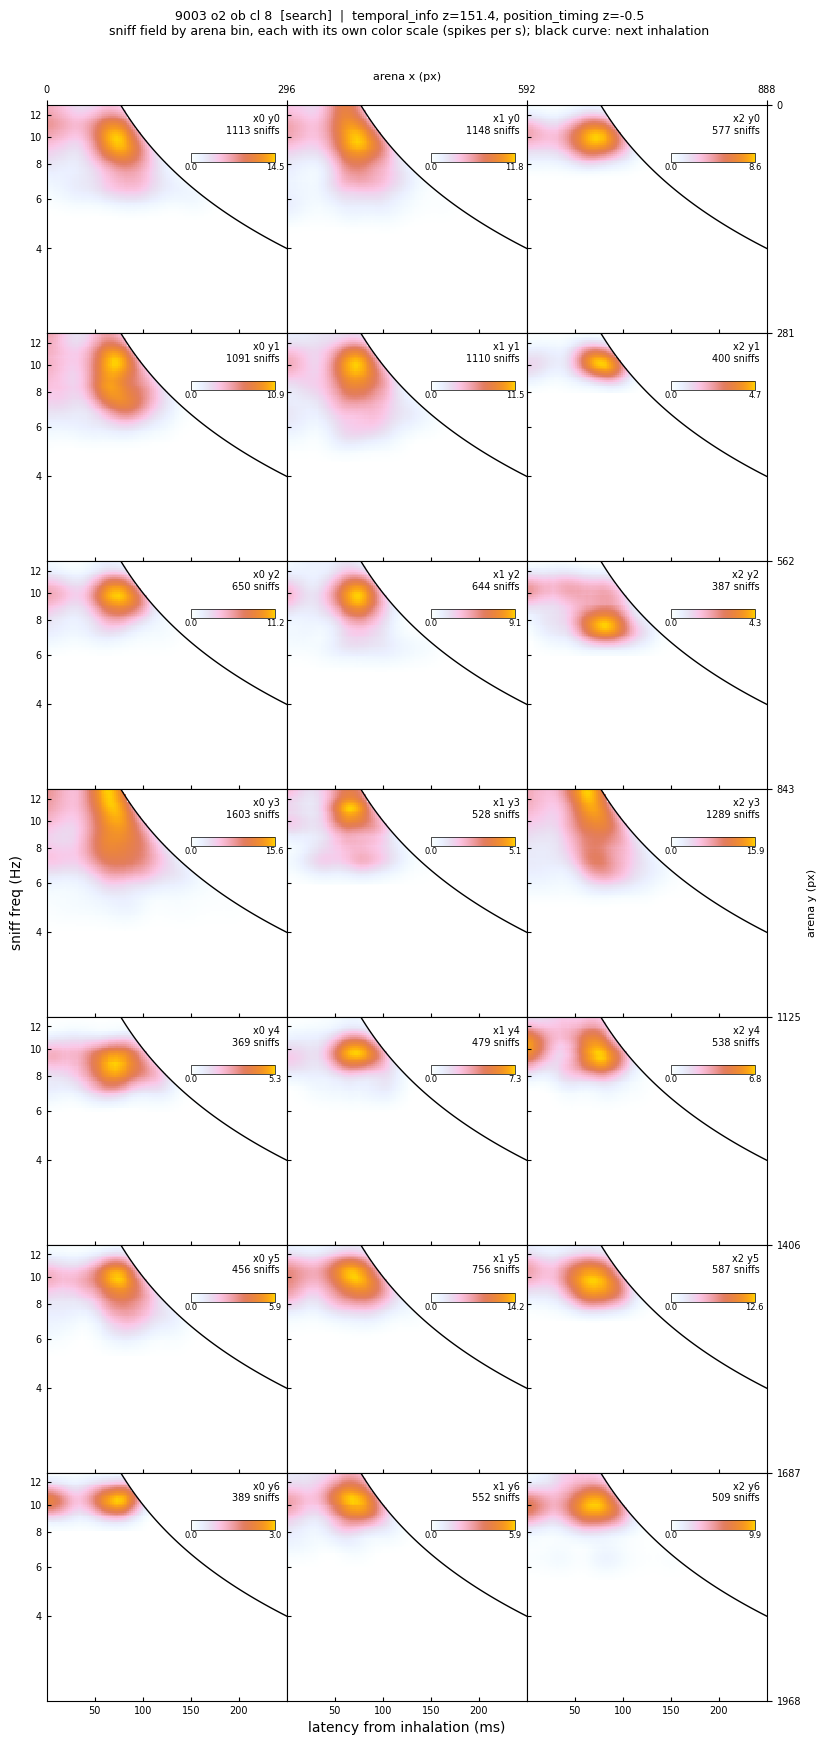

latency_ms             size_hz          
              x0    x1    x2      x0   x1   x2
y bin                                         
0           75.0  75.0  75.0     5.2  4.2  4.6
1           75.0  75.0  85.0     4.3  4.4  5.4
2           75.0  75.0  85.0     4.2  4.4  5.6
3           75.0  75.0  75.0     5.1  5.3  5.6
4           75.0  65.0  75.0     7.3  3.8  5.2
5           75.0  75.0  75.0     6.4  4.9  5.3
6           75.0  75.0  75.0     5.5  4.4  6.2

In [4]:
position_field('9003', 'o2', 8, show_deflection=False)